# Imports


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix,classification_report, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE




# Import des données

## Student Registration

In [2]:
studentRegistration = pd.read_csv('studentRegistration.csv')
studentRegistration.head()


,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159.0,NaN
1,AAA,2013J,28400,-53.0,NaN
2,AAA,2013J,30268,-92.0,12.0
3,AAA,2013J,31604,-52.0,NaN
4,AAA,2013J,32885,-176.0,NaN


## Assessments

In [3]:
assessments = pd.read_csv('assessments.csv')
print(assessments.shape)
assessments.head()





(206, 6)


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


In [4]:
assessments_weight = assessments[['id_assessment','weight']]
print(assessments_weight.shape)
assessments_weight.head()

(206, 2)


,id_assessment,weight
0,1752,10.0
1,1753,20.0
2,1754,20.0
3,1755,20.0
4,1756,30.0


## Student Assessment

In [5]:
studentAssessement= pd.read_csv('studentAssessment.csv')
print(studentAssessement.shape)
studentAssessement.head()



(173912, 5)


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0
3,1752,32885,26,0,69.0
4,1752,38053,19,0,79.0


## Student Info

In [6]:
studentInfo = pd.read_csv('studentInfo.csv')
print(studentInfo.shape)
studentInfo.head()


(32593, 12)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [7]:
studentInfo = studentInfo.copy()

studentInfo['id_with_presentation'] = (
    studentInfo['id_student'].astype(str)
    + '-' +
    studentInfo['code_presentation']
)
print(studentInfo.shape)
studentInfo.head()

(32593, 13)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,id_with_presentation
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,11391-2013J
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,28400-2013J
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,30268-2013J
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,31604-2013J
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,32885-2013J


## Courses

In [8]:
courses =pd.read_csv('courses.csv')
courses.head()


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240


## Student Vle

In [9]:
#studentVle = pd.read_csv('studentVle.csv')
#studentVle.head()


## Vle

In [10]:
vle = pd.read_csv('vle.csv')
vle.head()

,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,NaN,NaN
1,546712,AAA,2013J,oucontent,NaN,NaN
2,546998,AAA,2013J,resource,NaN,NaN
3,546888,AAA,2013J,url,NaN,NaN
4,547035,AAA,2013J,resource,NaN,NaN


## Jointure des données




### notes des devoirs de toutes les années

In [11]:
student_assessments_year = studentAssessement.join(assessments.set_index('id_assessment'), on='id_assessment', how='left')
print(student_assessments_year.shape)
student_assessments_year.head()

(173912, 10)


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


In [12]:
student_assessments_year = student_assessments_year.copy()

student_assessments_year['id_with_presentation'] = (
    student_assessments_year['id_student'].astype(str) + '-' + student_assessments_year['code_presentation'])
print(student_assessments_year.shape)
student_assessments_year.head()

(173912, 11)


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight,id_with_presentation
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0,11391-2013J
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0,28400-2013J
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0,31604-2013J
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0,32885-2013J
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0,38053-2013J


### Notes devoirs 2013

In [13]:
student_assessments_year_2013 = student_assessments_year[
    (student_assessments_year['code_presentation']=='2013J') |
    (student_assessments_year['code_presentation'] == '2013B')
]

print(student_assessments_year_2013.shape)
student_assessments_year_2013.head()

(82842, 11)


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight,id_with_presentation
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0,11391-2013J
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0,28400-2013J
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0,31604-2013J
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0,32885-2013J
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0,38053-2013J


### Notes devoirs 2014

In [14]:
student_assessments_year_2014 = student_assessments_year[
    (student_assessments_year['code_presentation'] == '2014J') |
    (student_assessments_year['code_presentation'] == '2014B')
]

print(student_assessments_year_2014.shape)
student_assessments_year_2014.head()

(91070, 11)


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight,id_with_presentation
1633,1758,569505,19,0,85.0,AAA,2014J,TMA,19.0,10.0,569505-2014J
1634,1758,570317,19,0,79.0,AAA,2014J,TMA,19.0,10.0,570317-2014J
1635,1758,574505,19,0,43.0,AAA,2014J,TMA,19.0,10.0,574505-2014J
1636,1758,588477,19,0,88.0,AAA,2014J,TMA,19.0,10.0,588477-2014J
1637,1758,593846,17,0,67.0,AAA,2014J,TMA,19.0,10.0,593846-2014J


### Etudiants 2013

In [15]:
student_2013 = studentInfo[ (studentInfo['code_presentation'] == '2013J') |
                            (studentInfo['code_presentation'] == '2013B')
                            ]

print(student_2013.shape)
student_2013.head()

(13529, 13)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,id_with_presentation
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,11391-2013J
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,28400-2013J
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,30268-2013J
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,31604-2013J
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,32885-2013J


Etudiants 2014

In [16]:
student_2014 = studentInfo[ (studentInfo['code_presentation'] == '2014J') |
                            (studentInfo['code_presentation'] == '2014B')
                            ]

print(student_2014.shape)
student_2014.head()

(19064, 13)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,id_with_presentation
383,AAA,2014J,6516,M,Scotland,HE Qualification,80-90%,55<=,0,60,N,Pass,6516-2014J
384,AAA,2014J,24734,F,South Region,Lower Than A Level,60-70%,0-35,0,60,N,Pass,24734-2014J
385,AAA,2014J,26192,F,East Anglian Region,A Level or Equivalent,60-70%,35-55,0,60,N,Distinction,26192-2014J
386,AAA,2014J,28061,M,Yorkshire Region,Lower Than A Level,40-50%,35-55,0,60,N,Pass,28061-2014J
387,AAA,2014J,31600,F,South West Region,A Level or Equivalent,40-50%,0-35,0,60,N,Pass,31600-2014J


# Data

## All

In [17]:
df_temp02 = student_assessments_year.merge(
    studentInfo,
    on='id_with_presentation',
    how='left',
    suffixes=('_assess', '_etud')
)
print(df_temp02.shape)
df_temp02.head()

(180871, 23)


,id_assessment,id_student_assess,date_submitted,is_banked,score,code_module_assess,code_presentation_assess,assessment_type,date,weight,...,id_student_etud,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0,...,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0,...,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0,...,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0,...,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0,...,38053,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,Pass


# Etudiant avec module

In [18]:
df_temp02['weighted_score'] = df_temp02['score'] * df_temp02['weight'] / 100

In [19]:
df_scores = (
    df_temp02.groupby(['id_with_presentation', 'code_module_assess'])['weighted_score']
    .sum()
    .reset_index()
)

In [20]:
df_modules = df_scores.pivot(
    index='id_with_presentation',
    columns='code_module_assess',
    values='weighted_score'
).reset_index().fillna(0)

In [21]:
df_unique = df_temp02.drop_duplicates(subset=['id_with_presentation'])

In [22]:
df_final = df_unique.merge(df_modules, on='id_with_presentation', how='left')

In [23]:
print(df_final.shape)
df_final.head()

(25262, 31)


,id_assessment,id_student_assess,date_submitted,is_banked,score,code_module_assess,code_presentation_assess,assessment_type,date,weight,...,disability,final_result,weighted_score,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0,...,N,Pass,7.8,82.4,0.0,0.0,0.0,0.0,0.0,0.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0,...,N,Pass,7.0,65.4,0.0,0.0,0.0,0.0,0.0,0.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0,...,N,Pass,7.2,76.3,0.0,0.0,0.0,0.0,0.0,0.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0,...,N,Pass,6.9,55.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0,...,N,Pass,7.9,66.9,0.0,0.0,0.0,0.0,0.0,0.0


In [24]:
df_final.columns.tolist()

['id_assessment',
 'id_student_assess',
 'date_submitted',
 'is_banked',
 'score',
 'code_module_assess',
 'code_presentation_assess',
 'assessment_type',
 'date',
 'weight',
 'id_with_presentation',
 'code_module_etud',
 'code_presentation_etud',
 'id_student_etud',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'weighted_score',
 'AAA',
 'BBB',
 'CCC',
 'DDD',
 'EEE',
 'FFF',
 'GGG']

In [25]:
df_final = df_final.drop(columns=[
    'id_student_etud',
    'code_presentation_etud',
    'code_module_etud',
    'weight',
    'date',
    'score',
    'is_banked',
    'date_submitted'
], errors='ignore')

In [26]:
print(df_final.shape)
# Affichage de toutes les colonnes
pd.set_option('display.max_columns', None)
df_final.head()

(25262, 23)


,id_assessment,id_student_assess,code_module_assess,code_presentation_assess,assessment_type,id_with_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,weighted_score,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,1752,11391,AAA,2013J,TMA,11391-2013J,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,7.8,82.4,0.0,0.0,0.0,0.0,0.0,0.0
1,1752,28400,AAA,2013J,TMA,28400-2013J,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,7.0,65.4,0.0,0.0,0.0,0.0,0.0,0.0
2,1752,31604,AAA,2013J,TMA,31604-2013J,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,7.2,76.3,0.0,0.0,0.0,0.0,0.0,0.0
3,1752,32885,AAA,2013J,TMA,32885-2013J,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,6.9,55.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1752,38053,AAA,2013J,TMA,38053-2013J,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,Pass,7.9,66.9,0.0,0.0,0.0,0.0,0.0,0.0


In [27]:
df_final.shape

(25262, 23)

# Copier les données sans les ids

In [28]:
df_no_id = df_final.drop(columns=[col for col in df_final.columns if 'id' in col.lower()])
df_no_id.head()



,code_module_assess,code_presentation_assess,assessment_type,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,weighted_score,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,AAA,2013J,TMA,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,7.8,82.4,0.0,0.0,0.0,0.0,0.0,0.0
1,AAA,2013J,TMA,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,7.0,65.4,0.0,0.0,0.0,0.0,0.0,0.0
2,AAA,2013J,TMA,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,7.2,76.3,0.0,0.0,0.0,0.0,0.0,0.0
3,AAA,2013J,TMA,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,6.9,55.0,0.0,0.0,0.0,0.0,0.0,0.0
4,AAA,2013J,TMA,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,Pass,7.9,66.9,0.0,0.0,0.0,0.0,0.0,0.0


In [29]:
df_no_id_copy=df_no_id.drop(columns=['weighted_score','code_presentation_assess'])
df_no_id_copy.head()

,code_module_assess,assessment_type,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,AAA,TMA,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,82.4,0.0,0.0,0.0,0.0,0.0,0.0
1,AAA,TMA,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,65.4,0.0,0.0,0.0,0.0,0.0,0.0
2,AAA,TMA,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,76.3,0.0,0.0,0.0,0.0,0.0,0.0
3,AAA,TMA,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,55.0,0.0,0.0,0.0,0.0,0.0,0.0
4,AAA,TMA,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,Pass,66.9,0.0,0.0,0.0,0.0,0.0,0.0


In [30]:
df_no_id_copy.shape

(25262, 18)

In [31]:
df_no_id_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25262 entries, 0 to 25261
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   code_module_assess    25262 non-null  object 
 1   assessment_type       25262 non-null  object 
 2   gender                25262 non-null  object 
 3   region                25262 non-null  object 
 4   highest_education     25262 non-null  object 
 5   imd_band              24294 non-null  object 
 6   age_band              25262 non-null  object 
 7   num_of_prev_attempts  25262 non-null  int64  
 8   studied_credits       25262 non-null  int64  
 9   disability            25262 non-null  object 
 10  final_result          25262 non-null  object 
 11  AAA                   25262 non-null  float64
 12  BBB                   25262 non-null  float64
 13  CCC                   25262 non-null  float64
 14  DDD                   25262 non-null  float64
 15  EEE                

# Début de l'analyse



In [32]:
df_final['final_result'].unique()

array(['Pass', 'Withdrawn', 'Fail', 'Distinction'], dtype=object)

# Nettoyer les doublons et les valeurs manquantes

In [33]:
#valeurs manquantes :
print('valeurs manquantes : \n' , df_final.isnull().sum())

#valeurs dupliquées :
print('valeurs dupliquées :', df_final.duplicated().sum())

valeurs manquantes : 
 id_assessment                 0
id_student_assess             0
code_module_assess            0
code_presentation_assess      0
assessment_type               0
id_with_presentation          0
gender                        0
region                        0
highest_education             0
imd_band                    968
age_band                      0
num_of_prev_attempts          0
studied_credits               0
disability                    0
final_result                  0
weighted_score               41
AAA                           0
BBB                           0
CCC                           0
DDD                           0
EEE                           0
FFF                           0
GGG                           0
dtype: int64
valeurs dupliquées : 0


In [34]:
df_no_id_copy['imd_band']= df_no_id_copy['imd_band'].fillna('unknown')



# Vérification

In [35]:
df_no_id_copy.columns.tolist()

['code_module_assess',
 'assessment_type',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'AAA',
 'BBB',
 'CCC',
 'DDD',
 'EEE',
 'FFF',
 'GGG']

In [36]:
print(df_no_id_copy.isna().sum())


code_module_assess      0
assessment_type         0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
AAA                     0
BBB                     0
CCC                     0
DDD                     0
EEE                     0
FFF                     0
GGG                     0
dtype: int64


In [37]:
df_no_id_copy['imd_band'].unique()


array(['90-100%', '20-30%', '50-60%', '80-90%', '30-40%', '70-80%',
       'unknown', '60-70%', '40-50%', '10-20', '0-10%'], dtype=object)

# Transformation des données

In [ ]:
# Création de la variable cible
df_no_id_copy['Pass'] = df_no_id_copy['final_result'].isin(['Pass','Distinction']).astype(int)

# Colonnes catégorielles 
categorical = ['code_module_assess',
               'assessment_type', 'gender',
                'disability']

df_no_id_copy_cat = pd.get_dummies(df_no_id_copy[categorical], drop_first=True)

# Colonnes numériques
numeric = ['num_of_prev_attempts', 'studied_credits',
           'AAA','BBB','CCC','DDD','EEE','FFF','GGG']
df_no_id_copy_num = df_no_id_copy[numeric]

#pour highest_education
def group_highest_education(v):
  if v== 'A Level or Equivalent':
      return 'A Level or Equivalent'
  if v== 'Lower Than A Level':
    return 'Lower Than A Level'
  else:
    return 'Other'

df_no_id_copy['highest_education_group'] = df_no_id_copy['highest_education'].apply(group_highest_education)

df_no_id_copy_highest_education = pd.get_dummies(df_no_id_copy['highest_education_group'], prefix='highest_education_', drop_first=False)

# Transformation IMD
def group_imd(v):
    if v == '20-30%':
        return '20_30'
    elif v == '30-40%':
        return '30_40'
    else:
        return 'other'

df_no_id_copy['imd_group'] = df_no_id_copy['imd_band'].apply(group_imd)

df_no_id_copy_imd = pd.get_dummies(df_no_id_copy['imd_group'], prefix='imd', drop_first=False)


#pour age
def group_age(v):
    if v == '0-35':
        return '0_35'
    elif v == '35-55':
        return '35_55'
    else:
        return 'other'

# Appliquer la fonction
df_no_id_copy['age_group'] = df_no_id_copy['age_band'].apply(group_age)

# One-hot encode les 3 groupes
df_no_id_copy_age = pd.get_dummies(df_no_id_copy['age_group'], prefix='age_band', drop_first=False)





# Variable cible
y = df_no_id_copy['Pass']

# Construction de la variable explicative
x = pd.concat([df_no_id_copy_imd,df_no_id_copy_age, df_no_id_copy_num,df_no_id_copy_highest_education, df_no_id_copy_cat], axis=1)

# Vérifications
print('shape de x est: ' + str(x.shape))




shape de x est: (25262, 28)


In [39]:
x.head()

,imd_20_30,imd_30_40,imd_other,age_band_0_35,age_band_35_55,age_band_other,num_of_prev_attempts,studied_credits,AAA,BBB,CCC,DDD,EEE,FFF,GGG,highest_education__A Level or Equivalent,highest_education__Lower Than A Level,highest_education__Other,code_module_assess_BBB,code_module_assess_CCC,code_module_assess_DDD,code_module_assess_EEE,code_module_assess_FFF,code_module_assess_GGG,assessment_type_Exam,assessment_type_TMA,gender_M,disability_Y
0,False,False,True,False,False,True,0,240,82.4,0.0,0.0,0.0,0.0,0.0,0.0,False,False,True,False,False,False,False,False,False,False,True,True,False
1,True,False,False,False,True,False,0,60,65.4,0.0,0.0,0.0,0.0,0.0,0.0,False,False,True,False,False,False,False,False,False,False,True,False,False
2,False,False,True,False,True,False,0,60,76.3,0.0,0.0,0.0,0.0,0.0,0.0,True,False,False,False,False,False,False,False,False,False,True,False,False
3,False,False,True,True,False,False,0,60,55.0,0.0,0.0,0.0,0.0,0.0,0.0,False,True,False,False,False,False,False,False,False,False,True,False,False
4,False,False,True,False,True,False,0,60,66.9,0.0,0.0,0.0,0.0,0.0,0.0,True,False,False,False,False,False,False,False,False,False,True,True,False


# Boxplot

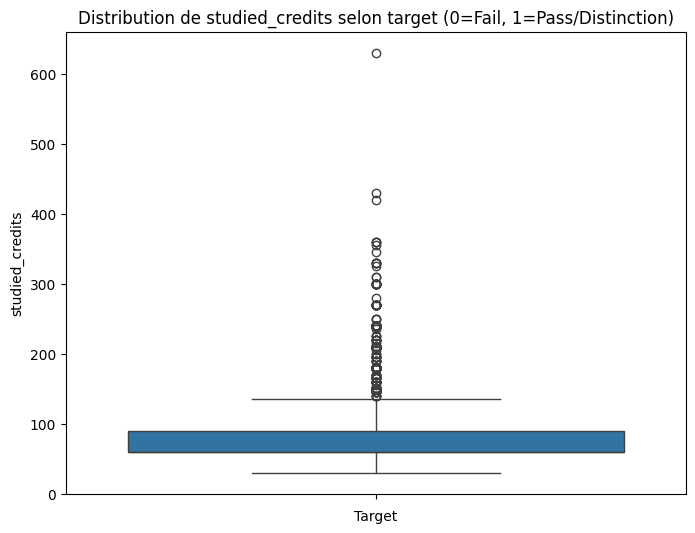

In [40]:
# Boxplots pour la colonne studied_credits
col='studied_credits'

plt.figure(figsize=(8, 6))
sns.boxplot(df_no_id_copy['studied_credits'])
plt.title(f'Distribution de {col} selon target (0=Fail, 1=Pass/Distinction)')
plt.xlabel("Target")
plt.ylabel(col)
plt.show()



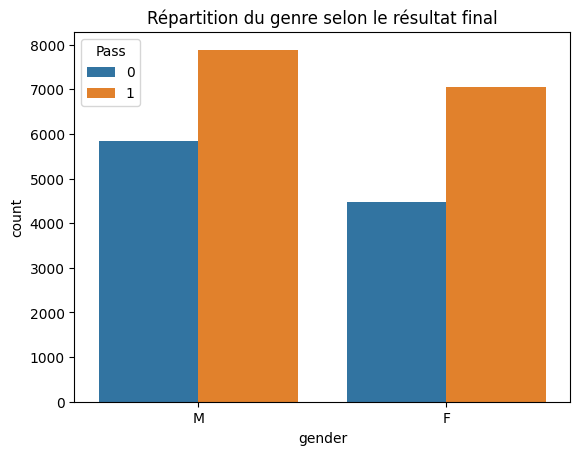

In [41]:
sns.countplot(data=df_no_id_copy, x='gender', hue='Pass')
plt.title("Répartition du genre selon le résultat final")
plt.show()


# Distribution de l'age

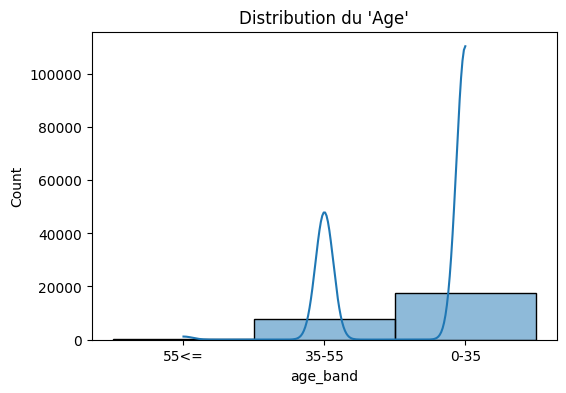

In [42]:
plt.figure(figsize=(6,4))
sns.histplot(df_no_id_copy['age_band'], bins=20, kde=True)
plt.title("Distribution du 'Age'")
plt.show()

# Matrice de corrélation

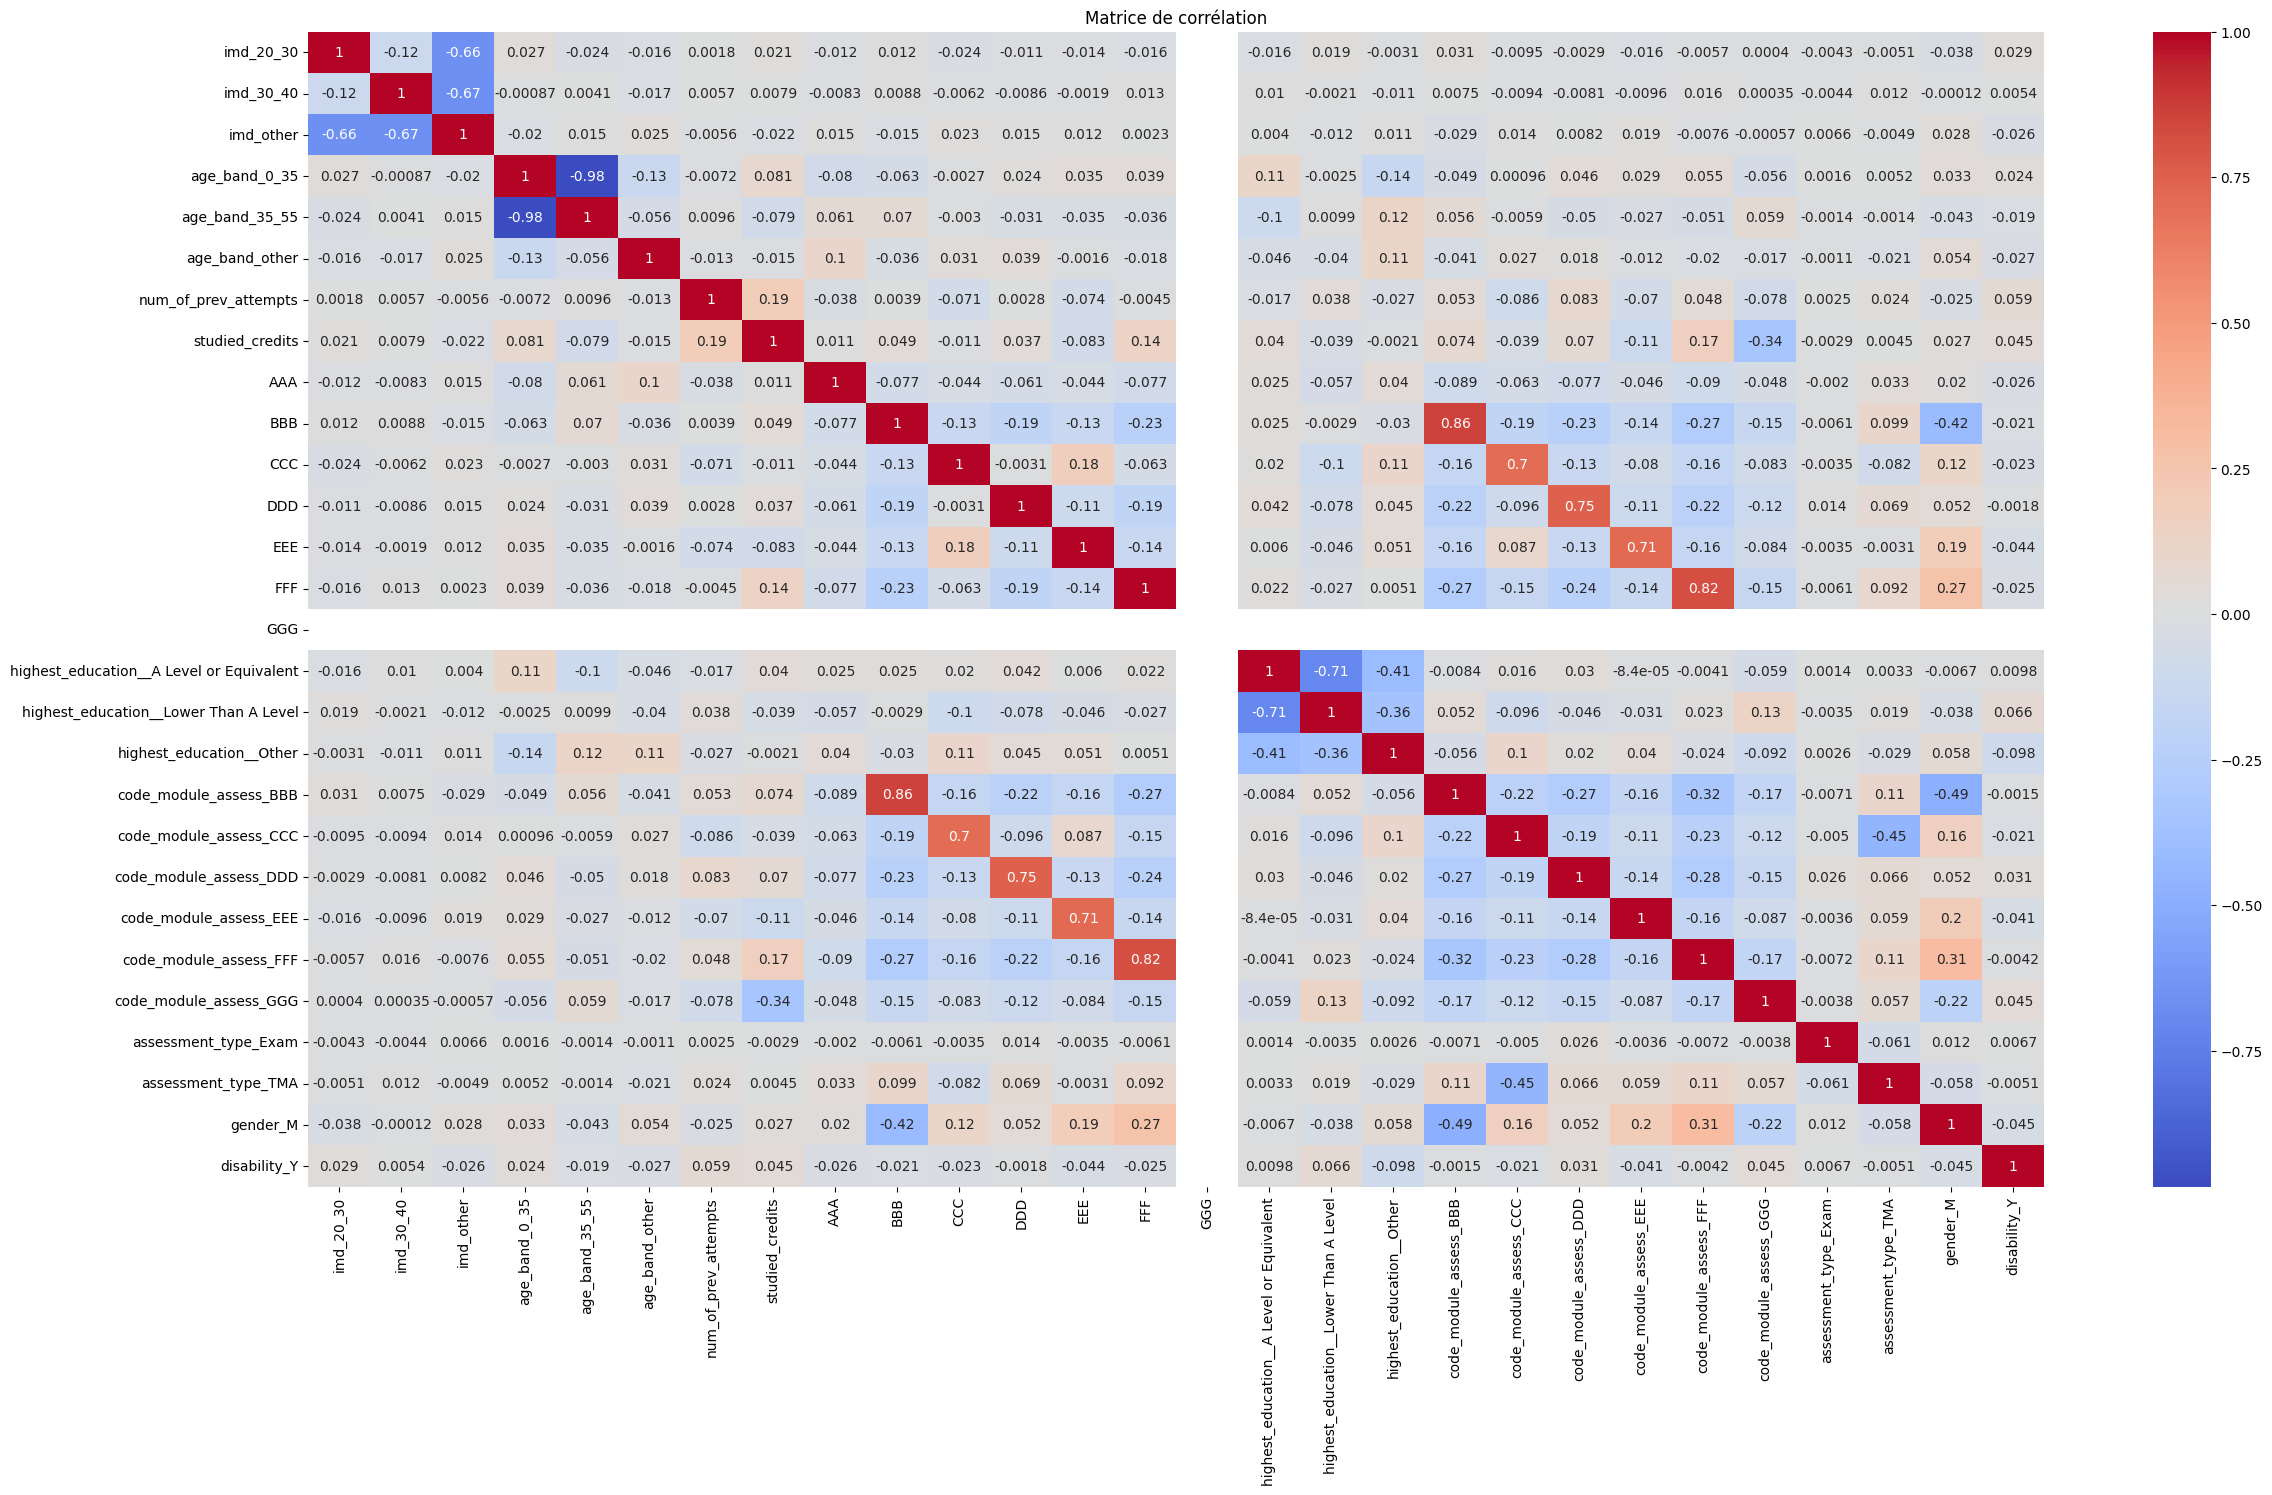

In [43]:
corr = x.corr(numeric_only=True)
plt.figure(figsize=(28,15))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

# Entrainement du modèle -regression logistique-

**Séparer les données**

In [44]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.3, random_state=42, stratify=y
)

x_valide, x_test, y_valide, y_test = train_test_split(
    x_test, y_test, test_size = 0.3)

**SMOTE pour équilibrer les données**

In [45]:
sm = SMOTE(random_state=42)
x_train_res, y_train_res = sm.fit_resample(x_train, y_train)


**Entrainer le modèle**

In [46]:
#Modèle : régrssion logistique

#scaler = StandardScaler()
#x_train[numeric] = scaler.fit_transform(x_train[numeric])
#x_test[numeric] = scaler.transform(x_test[numeric])

scaler = StandardScaler()

x_train_res[numeric] = scaler.fit_transform(x_train_res[numeric])
x_test[numeric] = scaler.transform(x_test[numeric])
x_valide[numeric] = scaler.transform(x_valide[numeric])


model = LogisticRegression(max_iter=3000)
model.fit(x_train_res, y_train_res)
print('le modèle est entrainé avec succcés')

le modèle est entrainé avec succcés


**Faire des prédictions**

In [47]:
y_pred = model.predict(x_test)
print("prédictions :" , y_pred)

print('le nombre d étudiant qui sont en test: ', y_pred.shape )

prédictions : [0 1 0 ... 1 1 1]
le nombre d étudiant qui sont en test:  (2274,)


**Evaluatio du modèle**

In [48]:
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy: ', accuracy)
print("\n")
print("Confusin matrix :\n", confusion_matrix(y_test, y_pred))
print("\n")
print("Classification report :\n", classification_report(y_test, y_pred))

Accuracy:  0.8808267370272648


Confusin matrix :
 [[ 723  209]
 [  62 1280]]


Classification report :
               precision    recall  f1-score   support

           0       0.92      0.78      0.84       932
           1       0.86      0.95      0.90      1342

    accuracy                           0.88      2274
   macro avg       0.89      0.86      0.87      2274
weighted avg       0.88      0.88      0.88      2274



In [49]:
y_pred_val = model.predict(x_valide)
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy: ', accuracy)


Accuracy:  0.8808267370272648


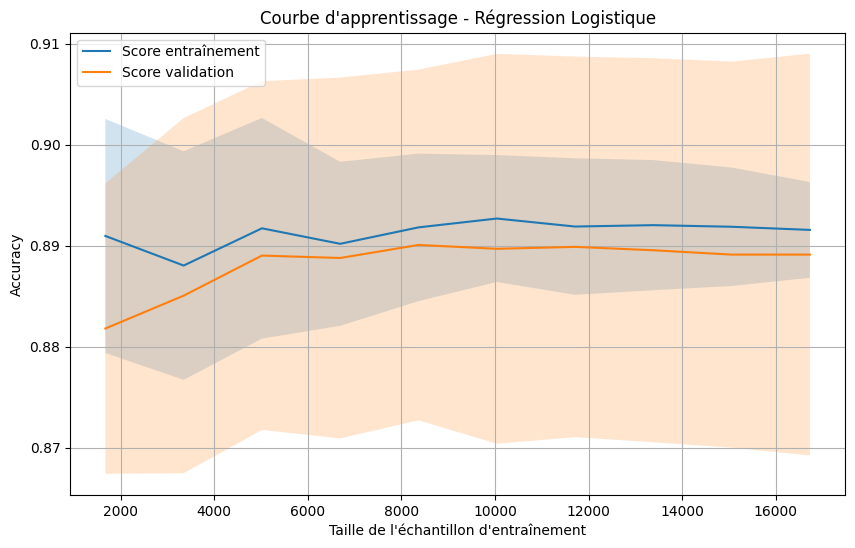

In [51]:
from sklearn.model_selection import learning_curve

model = LogisticRegression(max_iter=3000)

train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=x_train_res,
    y=y_train_res,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='accuracy',
    shuffle=True,
    random_state=42
)


train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean  = np.mean(test_scores, axis=1)
test_std  = np.std(test_scores, axis=1)


plt.figure(figsize=(10,6))
plt.plot(train_sizes, train_mean, label='Score entraînement')
plt.plot(train_sizes, test_mean, label='Score validation')

plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.2)

plt.title("Courbe d'apprentissage - Régression Logistique")
plt.xlabel("Taille de l'échantillon d'entraînement")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Entrainement de modele -Random Forest-

Analyse exploratoire

In [ ]:
# valeurs manquantes dans le dataset (il faut les enlevé pour ne pas fausser le model)
df_final.isnull().sum().sort_values(ascending=False)



,0
imd_band,968
weighted_score,41
id_assessment,0
code_presentation_assess,0
assessment_type,0
id_student_assess,0
code_module_assess,0
gender,0
id_with_presentation,0
highest_education,0


In [ ]:
# donne le nombre de doublon (il n'y en a aucun donc c'est bon)
df_final.duplicated().sum()

np.int64(0)

final_result
Pass           12016
Fail            5597
Withdrawn       4724
Distinction     2925
Name: count, dtype: int64


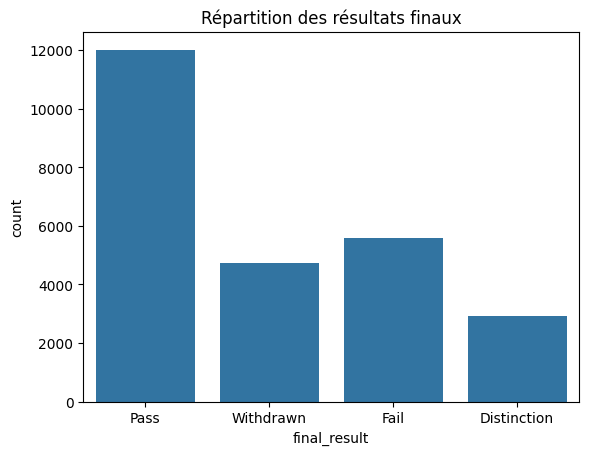

In [ ]:
#ON DOIT FAIRE UN SMOTE POUR EQUILIBREE LE JEUX DE DONNEE
import matplotlib.pyplot as plt
import seaborn as sns

# Compter les occurrences
print(df_final['final_result'].value_counts())

# Visualiser
sns.countplot(x='final_result', data=df_final)
plt.title("Répartition des résultats finaux")
plt.show()


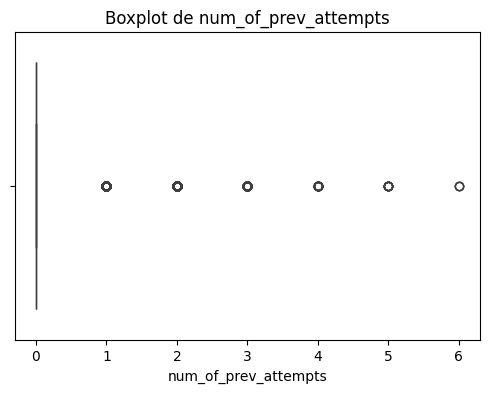

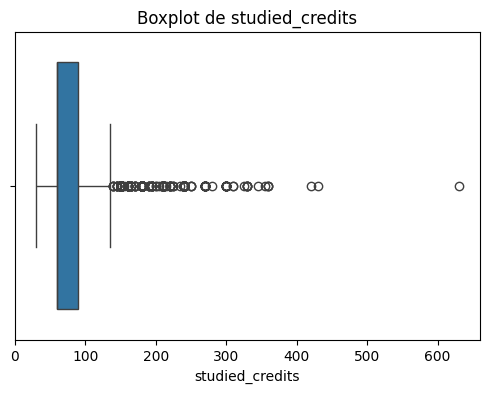

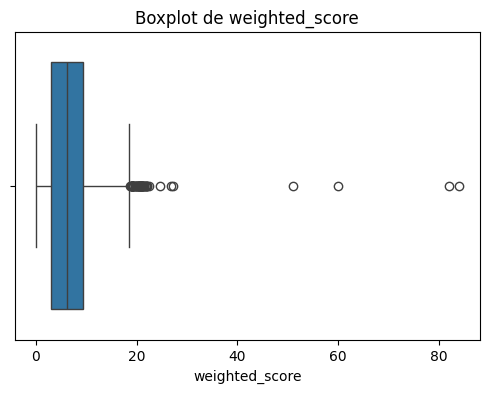

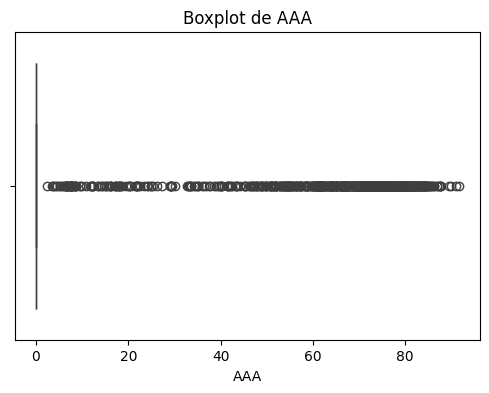

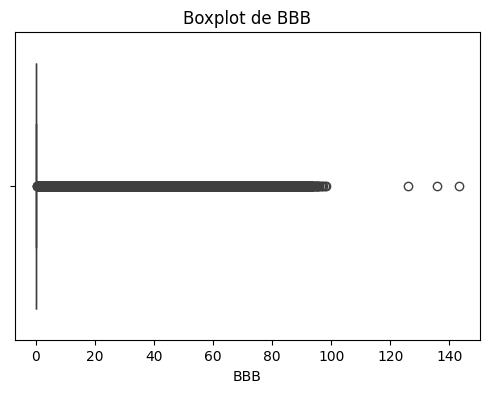

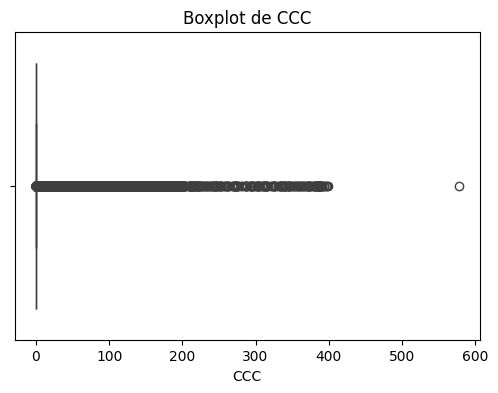

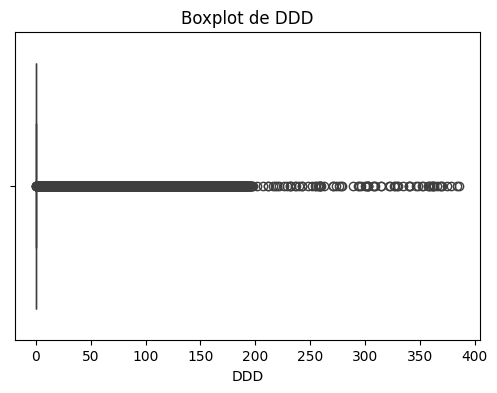

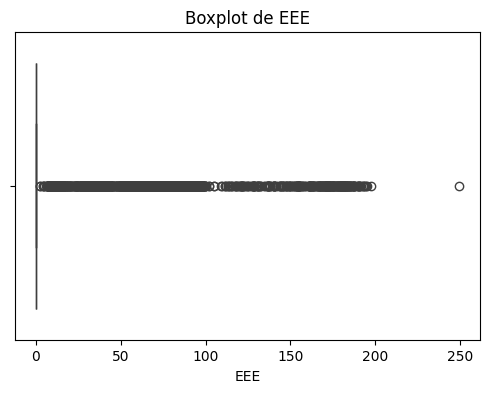

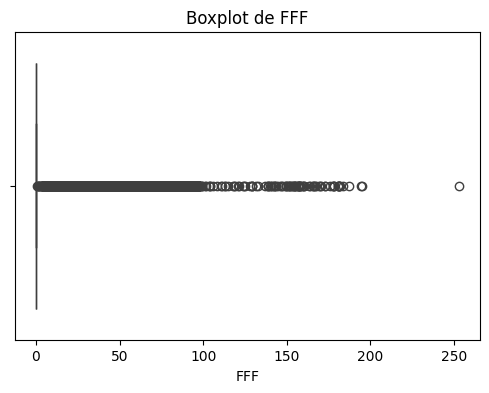

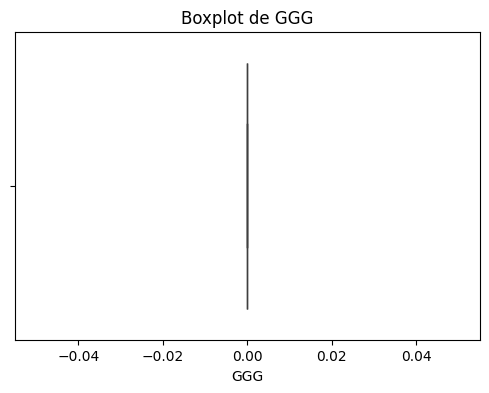

num_of_prev_attempts : 3138 outliers détectés
studied_credits : 1373 outliers détectés
weighted_score : 56 outliers détectés
AAA : 704 outliers détectés
BBB : 5873 outliers détectés
CCC : 3372 outliers détectés
DDD : 4939 outliers détectés
EEE : 2296 outliers détectés
FFF : 6252 outliers détectés
GGG : 0 outliers détectés


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Colonnes numériques à vérifier
num_cols = ['num_of_prev_attempts','studied_credits','weighted_score',
            'AAA','BBB','CCC','DDD','EEE','FFF','GGG']

# Visualiser les outliers avec boxplot
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df_final[col])
    plt.title(f'Boxplot de {col}')
    plt.show()

# Détection statistique des outliers (IQR)
for col in num_cols:
    Q1 = df_final[col].quantile(0.25)
    Q3 = df_final[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df_final[(df_final[col] < lower_bound) | (df_final[col] > upper_bound)]
    print(f"{col} : {len(outliers)} outliers détectés")

# Limiter les valeurs extrêmes avec clipping
for col in num_cols:
    Q1 = df_final[col].quantile(0.25)
    Q3 = df_final[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_final[col] = df_final[col].clip(lower=lower_bound, upper=upper_bound)
